In [2]:
#Runtime GPU/CPU
import torch
print("PyTorch version:",torch.__version__)
print("GPU available:",torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Using GPU:",torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("Using CPU")


PyTorch version: 2.11.0+cu128
GPU available: True
Using GPU: Tesla T4


In [3]:
#Required installations
#%pip -q install -U "transformers>=4.46,<5" "datasets>=3,<5" "accelerate>=1,<2" scikit-learn seaborn


In [4]:
#checking for package dependencies
import importlib.metadata as metadata

packages = [
    "transformers",
    "huggingface-hub",
    "diffusers",
    "gradio",
    "gradio-client",
    "datasets",
    "accelerate"
]

for package in packages:
    try:
        print(package, metadata.version(package))
    except metadata.PackageNotFoundError:
        print(package, "Not installed")


transformers 5.16.1
huggingface-hub 1.29.0
diffusers 0.40.0
gradio 6.26.0
gradio-client 2.6.1
datasets 4.8.5
accelerate 1.14.0


In [5]:
#checking
import torch
import transformers
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)

print("Transformers version:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("All BERT training imports successful!")


Transformers version: 5.16.1
GPU available: True
GPU: Tesla T4
All BERT training imports successful!


In [6]:

from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="/content/bert_checkpoints",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=torch.cuda.is_available(),
    report_to="none"
)

print("Training arguments created successfully!")


Training arguments created successfully!


In [7]:
import torch
from transformers import Trainer

print("GPU available:", torch.cuda.is_available())
print("Trainer imported successfully!")

GPU available: True
Trainer imported successfully!


In [8]:
from pathlib import Path

OUT = Path("/kaggle/working")
OUT.mkdir(parents=True, exist_ok=True)

In [9]:
import glob
import os
import pandas as pd
matches = glob.glob("/kaggle/input/**/data.csv", recursive=True)
assert matches, "data.csv not found - add the competition data via 'Add Input'"
DATA_DIR = os.path.dirname(matches[0])
print(DATA_DIR, os.listdir(DATA_DIR))
df = pd.read_csv(f"{DATA_DIR}/data.csv")

/kaggle/input/datasets/alexisbcook/jigsaw-snapshot ['data.csv']


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#df = pd.read_csv("Data")
df.head()
print("Dataset shape:",df.shape)
print("Columns:",list(df.columns))
display(df[['comment_text','target']].head(3))

Dataset shape: (90902, 45)
Columns: ['id', 'target', 'comment_text', 'severe_toxicity', 'obscene', 'identity_attack', 'insult', 'threat', 'asian', 'atheist', 'bisexual', 'black', 'buddhist', 'christian', 'female', 'heterosexual', 'hindu', 'homosexual_gay_or_lesbian', 'intellectual_or_learning_disability', 'jewish', 'latino', 'male', 'muslim', 'other_disability', 'other_gender', 'other_race_or_ethnicity', 'other_religion', 'other_sexual_orientation', 'physical_disability', 'psychiatric_or_mental_illness', 'transgender', 'white', 'created_date', 'publication_id', 'parent_id', 'article_id', 'rating', 'funny', 'wow', 'sad', 'likes', 'disagree', 'sexual_explicit', 'identity_annotator_count', 'toxicity_annotator_count']


,comment_text,target
0,haha you guys are a bunch of losers.,0.893617
1,Yet call out all Muslims for the acts of a few...,0.912500
2,This bitch is nuts. Who would read a book by a...,0.830769


In [11]:
#exploring dataset and checking for missing labels, texts, repeated text etc.,
print('missing texts', df.comment_text.isna().sum())
print('missing labels:', df.target.isna().sum())
print('repeated texts:', df.comment_text.duplicated().sum())
print('repeated labels:', df.target.duplicated().sum())
print('missing or balnk texts:',df.comment_text.fillna('').astype(str).str.strip().eq('').sum())
print('target range:',df.target.min(),df.target.max())
assert df.target.dropna().between(0,1).all(), 'unexpected target values'
identity_cols= [c for c in ['male','female', 'muslim', 'christian', 'jewish', 'balck', 'white',
     'homosexual_gay_or_lesbian','transgender','psychiatric_or mental_illness'] if c in df.columns]
print('identity annotation coverage:')
display((100*df[identity_cols].notna().mean()).round(1).sort_values())

missing texts 0
missing labels: 0
repeated texts: 764
repeated labels: 89480
missing or balnk texts: 0
target range: 0.0 1.0
identity annotation coverage:


male                         23.9
female                       23.9
muslim                       23.9
christian                    23.9
jewish                       23.9
white                        23.9
homosexual_gay_or_lesbian    23.9
transgender                  23.9
dtype: float64

In [12]:
#Cleaning
df = df.dropna(subset=['comment_text','target']).copy()
df['comment_text'] = df['comment_text'].astype(str)
df = df.loc[df.comment_text.str.strip().ne('')].copy()
df['label'] = (df.target >= 0.5).astype('int64')
df = df.reset_index(drop=True)
print('Usable rows:', len(df))
print('Label counts:')
print(df.label.value_counts())

Usable rows: 90902
Label counts:
label
1    45451
0    45451
Name: count, dtype: int64


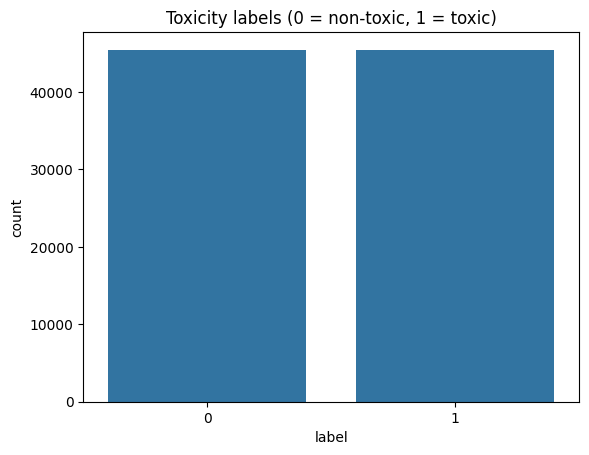

In [13]:
# visualising the class balance
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(data=df, x='label')
plt.title('Toxicity labels (0 = non-toxic, 1 = toxic)')
plt.show()

In [14]:
# tarin/ validation/test split
from sklearn.model_selection import GroupShuffleSplit
SEED=42
# Group by identical raw comment so repeated texts never cross partitions.
groups = df.comment_text.str.strip()
s1=GroupShuffleSplit(n_splits=1,test_size=0.20,random_state=SEED)
trainval_i,test_i=next(s1.split(df,df.label,groups))
trainval=df.iloc[trainval_i].copy(); test_df=df.iloc[test_i].copy()
s2=GroupShuffleSplit(n_splits=1,test_size=0.10,random_state=SEED)
tr_i,val_i=next(s2.split(trainval,trainval.label,trainval.comment_text.str.strip()))
train_df=trainval.iloc[tr_i].copy().reset_index(drop=True)
val_df=trainval.iloc[val_i].copy().reset_index(drop=True)
test_df=test_df.reset_index(drop=True)
for name,part in [('train',train_df),('val',val_df),('test',test_df)]:
    print(name,len(part),'toxic rate',round(part.label.mean(),4))
assert not (set(train_df.comment_text.str.strip()) & set(val_df.comment_text.str.strip()))
assert not (set(train_df.comment_text.str.strip()) & set(test_df.comment_text.str.strip()))
assert not (set(val_df.comment_text.str.strip()) & set(test_df.comment_text.str.strip()))
assert all(part.label.nunique()==2 for part in [train_df,val_df,test_df])
print('No exact-text leakage across splits.')
for name,part in [('train',train_df),('val',val_df),('test',test_df)]:
    part.to_csv(OUT/f'{name}_split.csv',index=False)

train 65475 toxic rate 0.4981
val 7278 toxic rate 0.4977
test 18149 toxic rate 0.5078
No exact-text leakage across splits.


In [15]:
import requests

url = "https://huggingface.co/google-bert/bert-base-uncased/resolve/main/config.json"

response = requests.get(url, timeout=20)
print("Status code:", response.status_code)

Status code: 200


In [16]:
from transformers import AutoModelForSequenceClassification

MODEL_NAME = "google-bert/bert-base-uncased"

model, loading_info = (
    AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        use_safetensors=True,
        output_loading_info=True
    )
)

print("Model loaded:", type(model).__name__)
print("Missing keys:", loading_info["missing_keys"])
print("Unexpected keys:", loading_info["unexpected_keys"])

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded: BertForSequenceClassification
Missing keys: {'classifier.bias', 'classifier.weight'}
Unexpected keys: {'cls.predictions.transform.LayerNorm.weight', 'cls.seq_relationship.bias', 'cls.predictions.transform.dense.weight', 'cls.seq_relationship.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.bias', 'cls.predictions.transform.dense.bias'}


In [17]:
#loading Tokenizer and prepare hugging Face datasets
from transformers import AutoTokenizer, DataCollatorWithPadding
from datasets import Dataset
MODEL_NAME='google-bert/bert-base-uncased'
MAX_LENGTH=128
tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME)
def encode_frame(frame):
    ds=Dataset.from_pandas(frame[['comment_text','label']].reset_index(drop=True))
    ds=ds.map(lambda batch:tokenizer(batch['comment_text'],truncation=True,max_length=MAX_LENGTH),batched=True)
    return ds.rename_column('label','labels').remove_columns(['comment_text'])
train_ds=encode_frame(train_df)
val_ds=encode_frame(val_df)
test_ds=encode_frame(test_df)
print(tokenizer.tokenize('I am a Christian person.'))
print(train_ds[0].keys())

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/65475 [00:00<?, ? examples/s]

Map:   0%|          | 0/7278 [00:00<?, ? examples/s]

Map:   0%|          | 0/18149 [00:00<?, ? examples/s]

['i', 'am', 'a', 'christian', 'person', '.']
dict_keys(['labels', 'input_ids', 'token_type_ids', 'attention_mask'])


In [18]:
#loading pretrained BERT with a new classification error
from transformers import AutoModelForSequenceClassification
model=AutoModelForSequenceClassification.from_pretrained(MODEL_NAME,num_labels=2)
print('Parameters:',sum(p.numel() for p in model.parameters()))
print('New classifier weights warning is expected.')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parameters: 109483778
New classifier weights warning is expected.


In [19]:
# Training Mode: fine Tuning Bert
from transformers import Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
from scipy.special import softmax

def compute_metrics(pred):
    logits,labels=pred
    probs=softmax(logits,axis=-1)[:,1]
    predicted=(probs>=0.5).astype(int)
    p,r,f1,_=precision_recall_fscore_support(labels,predicted,average='binary',zero_division=0)
    return {'accuracy':accuracy_score(labels,predicted),'precision':p,'recall':r,'f1':f1,'roc_auc':roc_auc_score(labels,probs)}

args=TrainingArguments(
    output_dir=str(OUT/'checkpoints'),
    num_train_epochs=2,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=1,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to='none',
    seed=SEED,
)
trainer=Trainer(model=model,args=args,train_dataset=train_ds,eval_dataset=val_ds,
    processing_class=tokenizer,data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics)
train_output=trainer.train()
print('Best checkpoint:',trainer.state.best_model_checkpoint)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,0.283531,0.291712,0.947788,0.939057,0.957206,0.948045,0.989182
2,0.173490,0.338297,0.950948,0.945430,0.956654,0.951009,0.989118


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Best checkpoint: /kaggle/working/checkpoints/checkpoint-4094


In [20]:
import transformers
print(transformers.__version__)

5.16.1


In [21]:
print("Best checkpoint:", trainer.state.best_model_checkpoint)

test_results = trainer.evaluate(test_ds)
print(test_results)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Best checkpoint: /kaggle/working/checkpoints/checkpoint-4094


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc
0.173490,0.334654,2,0.950410,0.942717,0.960720,0.951634,0.989742


{'eval_loss': 0.3346542418003082, 'eval_accuracy': 0.9504104909361397, 'eval_precision': 0.942717206132879, 'eval_recall': 0.9607204861111112, 'eval_f1': 0.9516337059329321, 'eval_roc_auc': 0.9897418059461952}


In [22]:
# Evaluate the best validation checkpoint on the test set
test_results = trainer.evaluate(
    eval_dataset=test_ds,
    metric_key_prefix="test"
)

print("\nFinal Test Results")
for key, value in test_results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc
0.173490,0.334654,2,0.950410,0.942717,0.960720,0.951634,0.989742



Final Test Results
test_loss: 0.3347
test_accuracy: 0.9504
test_precision: 0.9427
test_recall: 0.9607
test_f1: 0.9516
test_roc_auc: 0.9897


In [23]:
#Saving the best checkpoints and training history
import json
best_dir=OUT/'best_model'
trainer.save_model(str(best_dir))
tokenizer.save_pretrained(str(best_dir))
pd.DataFrame(trainer.state.log_history).to_csv(OUT/'training_history.csv',index=False)
config={'base_model':MODEL_NAME,'max_length':MAX_LENGTH,'seed':SEED,
        'epochs':2,'learning_rate':2e-5,'classification_threshold':0.5,
        'split_strategy':'GroupShuffleSplit by exact comment text',
        'train_rows':len(train_df),'val_rows':len(val_df),'test_rows':len(test_df)}
(OUT/'experiment_config.json').write_text(json.dumps(config,indent=2))
print('Saved model:',best_dir)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model: /kaggle/working/best_model


In [24]:
#Inference Mode: evaluating the test data set and saving the predictions
from sklearn.metrics import classification_report, confusion_matrix
out=trainer.predict(test_ds)
probs=softmax(out.predictions,axis=1)[:,1]
pred=(probs>=0.5).astype(int)
print(classification_report(test_df.label,pred,zero_division=0))
print('Test ROC-AUC:',roc_auc_score(test_df.label,probs))
print('Confusion matrix:\n',confusion_matrix(test_df.label,pred))
predictions=test_df.copy()
predictions['toxicity_score']=probs
predictions['predicted_label']=pred
predictions['prediction_confidence']=np.maximum(probs,1-probs)
predictions['correct']=(pred==test_df.label.to_numpy())
predictions.to_csv(OUT/'test_predictions.csv',index=False)
print('Saved',OUT/'test_predictions.csv',len(predictions),'rows')

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

           0       0.96      0.94      0.95      8933
           1       0.94      0.96      0.95      9216

    accuracy                           0.95     18149
   macro avg       0.95      0.95      0.95     18149
weighted avg       0.95      0.95      0.95     18149

Test ROC-AUC: 0.9897418059461952
Confusion matrix:
 [[8395  538]
 [ 362 8854]]
Saved /kaggle/working/test_predictions.csv 18149 rows


In [25]:
from pathlib import Path
from IPython.display import FileLink, display
from scipy.special import softmax
from transformers import AutoModelForSequenceClassification
import pandas as pd
import numpy as np
import transformers
import torch
import json
import zipfile

# Zielordner
export_dir = Path("/kaggle/working/bert_project_export")
export_dir.mkdir(parents=True, exist_ok=True)

# 1. Modell und Tokenizer speichern
model_dir = export_dir / "best_model"
trainer.save_model(str(model_dir))
tokenizer.save_pretrained(str(model_dir))

# 2. Genau verwendete Datensplits speichern
train_df.to_csv(export_dir / "train_split.csv", index=False)
val_df.to_csv(export_dir / "val_split.csv", index=False)
test_df.to_csv(export_dir / "test_split.csv", index=False)

# 3. Testmetriken erneut berechnen und speichern
test_metrics = trainer.evaluate(
    eval_dataset=test_ds,
    metric_key_prefix="test"
)

with open(export_dir / "test_metrics.json", "w", encoding="utf-8") as file:
    json.dump(test_metrics, file, indent=2, default=lambda x: float(x))

# 4. Einzelne Testvorhersagen speichern
prediction_output = trainer.predict(test_ds)
probabilities = softmax(prediction_output.predictions, axis=1)[:, 1]
predicted_labels = (probabilities >= 0.5).astype(int)

test_predictions = test_df.copy().reset_index(drop=True)
test_predictions["toxicity_score"] = probabilities
test_predictions["predicted_label"] = predicted_labels
test_predictions["prediction_confidence"] = np.maximum(
    probabilities, 1 - probabilities
)
test_predictions["correct"] = (
    predicted_labels == test_predictions["label"].to_numpy()
)

test_predictions.to_csv(
    export_dir / "test_predictions.csv",
    index=False
)

# 5. Trainingsverlauf speichern
pd.DataFrame(trainer.state.log_history).to_csv(
    export_dir / "training_history.csv",
    index=False
)

# 6. Experiment-Konfiguration speichern
experiment_config = {
    "base_model": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "seed": SEED,
    "epochs": 2,
    "learning_rate": 2e-5,
    "train_batch_size": 16,
    "evaluation_batch_size": 32,
    "weight_decay": 0.01,
    "classification_threshold": 0.5,
    "split_strategy": "GroupShuffleSplit by stripped exact comment text",
    "train_rows": len(train_df),
    "validation_rows": len(val_df),
    "test_rows": len(test_df),
    "best_checkpoint": str(trainer.state.best_model_checkpoint),
    "transformers_version": transformers.__version__,
    "torch_version": torch.__version__
}

with open(export_dir / "experiment_config.json", "w", encoding="utf-8") as file:
    json.dump(experiment_config, file, indent=2)

# 7. Prüfen, ob das gespeicherte Modell vollständig geladen werden kann
verification_model, loading_info = (
    AutoModelForSequenceClassification.from_pretrained(
        str(model_dir),
        output_loading_info=True
    )
)

print("Missing keys:", loading_info["missing_keys"])
print("Unexpected keys:", loading_info["unexpected_keys"])

if loading_info["missing_keys"] or loading_info["unexpected_keys"]:
    raise RuntimeError(
        "Das gespeicherte Modell konnte nicht vollständig geladen werden."
    )

del verification_model

# 8. Alles in ein einziges ZIP packen
zip_path = Path("/kaggle/working/bert_project_export.zip")

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_STORED
) as archive:
    for path in export_dir.rglob("*"):
        if path.is_file():
            archive.write(
                path,
                path.relative_to(export_dir.parent)
            )

print(f"Export erstellt: {zip_path}")
print(f"Größe: {zip_path.stat().st_size / 1024**2:.1f} MB")

# Anklickbarer Download-Link
display(FileLink(str(zip_path)))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc
0.173490,0.334654,2,0.950410,0.942717,0.960720,0.951634,0.989742


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Missing keys: set()
Unexpected keys: set()
Export erstellt: /kaggle/working/bert_project_export.zip
Größe: 463.6 MB


/kaggle/working/bert_project_export.zip

  0%|          | 0/157 [00:00<?, ?it/s]

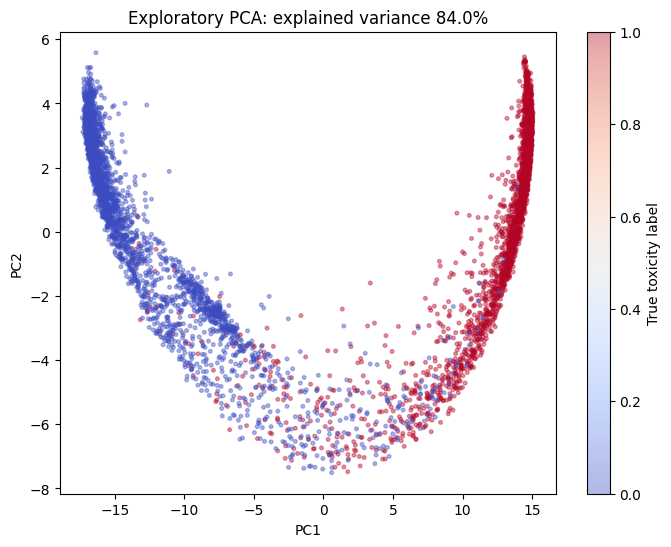

Embedding shape: (5000, 768)


In [26]:
#bert embeddings for PCA
from tqdm.auto import tqdm
from sklearn.decomposition import PCA
# Use a deterministic subset to limit memory and GPU time.
sample=test_df.sample(n=min(5000,len(test_df)),random_state=SEED).sort_index()
texts=sample.comment_text.tolist()
bert=trainer.model.bert
bert.eval()
device=next(bert.parameters()).device
vectors=[]
for start in tqdm(range(0,len(texts),32)):
    batch=tokenizer(texts[start:start+32],padding=True,truncation=True,
                    max_length=MAX_LENGTH,return_tensors='pt').to(device)
    with torch.no_grad():
        v=bert(**batch).last_hidden_state[:,0,:]
    vectors.append(v.float().cpu().numpy())
embeddings=np.concatenate(vectors,axis=0)
np.save(OUT/'pca_embeddings.npy',embeddings)
# PCA is fitted here only for a preliminary visual check. For a rigorous comparison,
# fit PCA on shared training/validation embeddings and transform held-out embeddings.
pca=PCA(n_components=2,random_state=SEED)
coords=pca.fit_transform(embeddings)
np.save(OUT/'pca_coordinates.npy',coords)
sample.to_csv(OUT/'pca_sample_metadata.csv',index=False)
plt.figure(figsize=(8,6))
plt.scatter(coords[:,0],coords[:,1],c=sample.label.to_numpy(),cmap='coolwarm',s=7,alpha=.4)
plt.title(f'Exploratory PCA: explained variance {pca.explained_variance_ratio_.sum():.1%}')
plt.xlabel('PC1');plt.ylabel('PC2');plt.colorbar(label='True toxicity label');plt.show()
print('Embedding shape:',embeddings.shape)